# Committor from an infretis StapleTIS Run (1D Underdamped Langevin)

Fits the committor of an **underdamped** 1D system from the paths of an **infretis StapleTIS** simulation (ASE engine, `integrator = "langevin"`) with NPNEq (`CommittorNE`, CuPy). At low friction the committor depends on the velocity as well, q(x, v), so the notebook has two fits that bring the velocity in differently: **x with histories**, and **x and v as CVs without histories**.

**How the paths become training data** (the same code as `infretis_staple_1d.ipynb`: `tis_data.prepare_data`, which switches to `infretis_data.py` for infretis runs; details in `docs/npneq_tis_notes.md`, sections 3, 9 and 15):
- **Read with infretis' own definitions:** interfaces and swap settings from `infretis.toml`, one row per finished path from `infretis_data.txt`, the order parameters from `load/<pnr>/order.txt` (or an h5 archive), and each path's core in an ensemble from infretis' `StaplePath.get_sh_region`.
- **Cut at M, mirrored pieces:** every (path, ensemble) pair gives the piece from its first frame past M; with `REVERSED` also the part before the last M crossing, read backwards. **Velocities are odd under time reversal:** a recorded velocity is negated in the mirrored pieces (`--odd-columns`), a finite-difference velocity is recomputed backwards.
- **Weights:** `path_f / path_w` (`'staple'`) with swaps, `path_f` (`'rejections'`) with shooting only; `WEIGHTINGS = [None]` takes the run's default.

**The run** is an infretis folder (`infretis.toml`, `infretis_data.txt`, `archive.h5` or `load/`) of a particle in 1D with Langevin dynamics (default folder `data/infretis_inputs/well_lgv`; the other 1D folders there are overdamped). `order.txt` has the time and the position x (the order parameter); a velocity written by the order parameter class can be named in `V_COLUMN`, otherwise the finite-difference velocity is used (`VELOCITY = 'fd'`). A: λ ≤ `LAMBDA_A`, B: λ ≥ `LAMBDA_B`.

**Exact committor:** there is none in general. If you have the brute-force q(x, v) of the same system (an `.npz` with `xs`, `vs`, `q`, e.g. `figures_by_potential/1d_cos_well/langevin_staple/checks/reference.npz` for the toytis well with γ = 1, kT = 1, m = 1), set `REF_FILE`; the notebook then prints the RMS and shows fit − exact. Its velocity axis must match `V_SCALE × velocity column`.


## 1. Imports

In [1]:
import argparse
import os
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cupy as cp
from scipy.interpolate import RegularGridInterpolator

plt.rc('font', size=10)
plt.rc('axes', titlesize=12)
plt.rc('axes', labelsize=12)
plt.rc('legend', fontsize=9)

# Run from examples/: the CuPy optimalrcs package and the path readers of the examples
REPO = os.path.abspath(os.path.join(os.getcwd(), os.pardir))
sys.path.insert(0, f'{REPO}/optimalrcs-cupy/')
sys.path.insert(0, f'{REPO}/examples/')
import optimalrcs
import tis_data
import infretis_data
import seed_runs
FIG = f'{REPO}/examples/figures_by_potential'

## 2. Settings

**Run and data**

| Name | Meaning |
|---|---|
| `TIS_DIR` | the infretis simulation folder (`infretis.toml`, `infretis_data.txt`, `load/`) |
| `H5_FILE` | order parameters from an `inft store_txt -order` archive instead of `load/` (`None`: use `load/`) |
| `LAMBDA_A`, `LAMBDA_B` | states A (λ ≤ λ_A) and B (λ ≥ λ_B); `None`: the first and last interface |
| `BURN_IN_FRACTION` | the first part of the rows of `infretis_data.txt` (the order in which the paths ended) is skipped; the initial load paths always are |
| `PATHS_PER_ENSEMBLE`, `THIN` | at most this many paths per ensemble, evenly spaced (`None`: all), after keeping every `THIN`-th |
| `VELOCITY` | `'fd'`: the velocity from the positions (change of x over `FD_STEPS` frames, computed before the cut; backwards in mirrored pieces); `'recorded'`: column `V_COLUMN` of `order.txt` (time = 0, x = 1), negated in mirrored pieces |
| `V_SCALE` | v = velocity column × `V_SCALE` (for `'fd'`: 1 / time per frame, in the units of the reference) |
| `REF_FILE` | brute-force q(x, v) `.npz` (`xs`, `vs`, `q`) for the comparison; `None`: no reference |
| `REVERSED` | also use the mirrored pieces (time-reversible dynamics at equilibrium) |
| `WEIGHTINGS` | the weightings to fit, one fit each: `None` = the run's default, `'staple'` = path_f / path_w, `'rejections'` = path_f, `'none'` = 1 per (path, ensemble). One entry is enough; list several to compare them |

**Fit** (the same for every weighting; the history fit uses `HISTORY` and `MAX_ITER_HIST`, the (x, v) fit `MAX_ITER_XV`): `SEEDS` (which CV and envelope centre each iteration draws), a warm-up of `WARMUP_ITER` iterations with a wide envelope, then `MAX_ITER` iterations, in chunks of `CHUNK` after which the plots are shown and saved. `STOPPED_ENDS` (default `True`): a piece that ends outside A and B was stopped by the path's own end (a turn); the stopped Z_q then uses q at that end for windows that pass it (`set_stopped_traj_end`), and the A/B traps are made long enough that no window is dropped. `NY` is the degree of the polynomial basis, `LAZY_BASIS` evaluates it on the fly (GPU memory).

In [2]:
TIS_DIR = f'{REPO}/examples/figures_by_potential/_shared/param_lambda/op_loop/loop_well_lgv/production_seed/'
H5_FILE = None  # None: read load/<pnr>/order.txt
LAMBDA_A, LAMBDA_B = -0.35, 0.35    # None: first and last interface
BURN_IN_FRACTION = 0.3
PATHS_PER_ENSEMBLE = 3000           # None: all paths after the burn-in
THIN = 1
REVERSED = True
WEIGHTINGS = ['rejections']                 # e.g. [None], ['staple', 'rejections']

VELOCITY = 'recorded'                     # 'fd' or 'recorded' (a velocity column in order.txt)
V_COLUMN = 2# 'recorded': column of the velocity in order.txt (time = 0, x = 1)
FD_STEPS = 1                        # 'fd': the velocity is the change of x over this many frames, per frame
V_SCALE = 1.0                       # v = velocity column * V_SCALE ('fd': 1 / time per frame)
REF_FILE = f'{REPO}/examples/figures_by_potential/1d_cos_well/exact/q_exact_ASE.npz'                     # brute-force q(x, v) .npz with xs, vs, q; None: no reference

SEEDS = [0]
WARMUP_ITER, WARMUP_ENVELOPE = 1000, 1
HISTORY = [0, 1]                    # fit A: lags d drawn each iteration (0: no lag); x only
MAX_ITER_HIST = 10000                # fit A: main iterations
MAX_ITER_XV = 10000                  # fit B: x and v as CVs, no history
CHUNK = 1000
ENVELOPE, GAMMA = 0.01, 0.1
STOPPED_ENDS = True                 # stopped Z_q: a window passing a turn end of a piece uses q at that end
NY, LAZY_BASIS = 6, True            # basis degree; evaluate the basis on the fly (GPU memory)
PLOTS = ('metrics', 'tis', 'feps', 'obs_pred')          # library plots after every chunk; also possible: 'feps', 'obs_pred'
LABEL = 'position $x$ (order parameter $\\lambda$)'
N_BINS = 80                         # bins along lambda for the profiles

RUN_NAME = os.path.basename(TIS_DIR.rstrip('/'))
OUT = f'{FIG}/1d_cos_well/infretis_langevin_staple/{RUN_NAME}'
print('figures and results in', OUT)


figures and results in /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/1d_cos_well/infretis_langevin_staple/production_seed


## 3. The Run

What infretis wrote: the sampling settings, and per ensemble its window (L, M, R), the number of finished paths with a nonzero occupancy, their total occupancy `path_f`, and the share of that occupancy with `path_w` ≠ 1 (where `'staple'` and `'rejections'` differ).

**Weight check** (`infretis_data.weight_consistency`, needs no committor). A path that is valid in two ensembles e and e′ should split its occupancy in the same ratio C_e / C_e′ whatever its type. So the ratio Σ weight_e / Σ weight_e′ over paths of one class (w_e, w_e′) must not depend on the class: relative to class (1, 1), the classes (0.5, 1) and (1, 0.5) should give 1 for the right weighting. Runs with swaps show which one that is. Runs with shooting only have no paths shared between ensembles, and the check is empty.

In [3]:
settings = infretis_data.read_settings(TIS_DIR)
table = infretis_data.read_infretis_data(os.path.join(TIS_DIR, 'infretis_data.txt'), len(settings['interfaces']))
default_w, why = infretis_data.default_weighting(settings)
print(f"mode {settings['mode']}, infinite swap {settings['infinite_swap']}, staple swap fraction "
      f"{settings['staple_swap_frac']}, {len(table['pnr'])} finished paths")
print(f"interfaces {settings['interfaces']}")
print(f"default weighting: {default_w} ({why})")

f, w = table['path_f'], table['path_w']
rows = []
for e in range(len(settings['interfaces'])):
    on = f[:, e] > 0
    rows.append(dict(ensemble=f'{e:03d}', window=tuple(round(v, 4) for v in infretis_data.ensemble_window(settings, e)),
                     paths=int(on.sum()), occupancy=f[on, e].sum(),
                     share_w_not_1=(f[on, e] * ~np.isclose(w[on, e], 1)).sum() / max(f[on, e].sum(), 1e-12)))
display(pd.DataFrame(rows).set_index('ensemble').round(3))

check = infretis_data.weight_consistency(table)
w_not_1 = ((f > 0) & ~np.isclose(w, 1)).any()
if not w_not_1:
    print("path_w is 1 for every occupied (path, ensemble) pair (no wire fencing, no staple weights): 'staple' (path_f / path_w) "
          "and 'rejections' (path_f) are the same weights for this run, and the weight check below has nothing to compare")
if not check:
    print('weight check: no class of paths with w != 1 that is shared by two ensembles' if not w_not_1 else
          'weight check: no pairs of ensembles with enough shared paths (expected for shooting only)')
else:
    out = []
    for row in check:
        for c in ((0.5, 1), (1, 0.5)):
            if c in row:
                out.append(dict(pair=row['pair'], cls=c, n=row['n'][c],
                                path_f=f"{row[c]['rejections'][0]:.3f} ± {row[c]['rejections'][1]:.3f}",
                                path_f_over_w=f"{row[c]['staple'][0]:.3f} ± {row[c]['staple'][1]:.3f}"))
    display(pd.DataFrame(out))

mode staple, infinite swap True, staple swap fraction 0.5, 58064 finished paths
interfaces [-0.35, -0.25, -0.15, -0.05, 0.05, 0.15, 0.25, 0.35]
default weighting: staple (StapleTIS with infinite swap: the permanent of W splits the occupancies by w)


,window,paths,occupancy,share_w_not_1
ensemble,,,,
000,"(-inf, -0.35, -0.35)",9871,54676.000,0.000
001,"(-0.35, -0.35, -0.25)",26788,54885.875,0.000
002,"(-0.35, -0.25, -0.15)",27329,61134.547,0.014
003,"(-0.25, -0.15, -0.05)",33670,60798.052,0.213
004,"(-0.15, -0.05, 0.05)",39663,61066.005,0.297
005,"(-0.05, 0.05, 0.15)",39589,60887.792,0.288
006,"(0.05, 0.15, 0.25)",32413,61277.090,0.218
007,"(0.15, 0.25, 0.35)",24823,60841.639,0.014


,pair,cls,n,path_f,path_f_over_w
0,"(2, 3)","(0.5, 1)",434,0.486 ± 0.016,0.972 ± 0.031
1,"(2, 4)","(0.5, 1)",405,0.451 ± 0.018,0.903 ± 0.036
2,"(2, 5)","(0.5, 1)",307,0.446 ± 0.019,0.891 ± 0.037
3,"(2, 5)","(1, 0.5)",2695,2.026 ± 0.040,1.013 ± 0.020
4,"(2, 6)","(0.5, 1)",257,0.476 ± 0.029,0.952 ± 0.057
5,"(2, 6)","(1, 0.5)",3317,1.976 ± 0.024,0.988 ± 0.012
6,"(2, 7)","(0.5, 1)",248,0.434 ± 0.032,0.868 ± 0.064
7,"(2, 7)","(1, 0.5)",281,2.090 ± 0.084,1.045 ± 0.042
8,"(3, 4)","(0.5, 1)",5144,0.488 ± 0.007,0.976 ± 0.014
9,"(3, 5)","(0.5, 1)",3652,0.484 ± 0.007,0.969 ± 0.014


## 4. From Paths to Frames

`tis_data.prepare_data` reads the run once per weighting in `WEIGHTINGS` (the pieces are the same, only their weights differ). It returns per frame: the CVs, λ, the time within its path (`t_traj`), its piece (`i_traj`), its path (`group_traj`, the infretis path number), the path weight (`path_weights`, mean 1) and the A/B masks.

The plots show where the frames are: the weighted number of frames along λ (the path-sampling density, high at the interfaces where pieces start, not the equilibrium distribution), and the piece lengths.

State A: order <= -0.35, state B: order >= 0.35
infretis run /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/_shared/param_lambda/op_loop/loop_well_lgv/production_seed/: mode staple, infinite swap True, 8 ensembles, 58064 finished paths in /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/_shared/param_lambda/op_loop/loop_well_lgv/production_seed/infretis_data.txt
Interfaces: [-0.35, -0.25, -0.15, -0.05, 0.05, 0.15, 0.25, 0.35]
  path_w != 1 for 34125 (path, ensemble) pairs, 13.4% of the occupancy; path_f and path_f / path_w differ there by a factor [2.]
  Note (StapleTIS): path_f / path_w is the natural measure of the stored staple paths (crossing probabilities, rates). For committor pieces use path_f (--weights rejections): an LML/RMR core is stored twice, once with each turn (the extension's coin flip, w = 1/2 each), and path_f counts the core once; see docs/op_loop_report.md.
Order parameters from /local/data/data-fbsskr

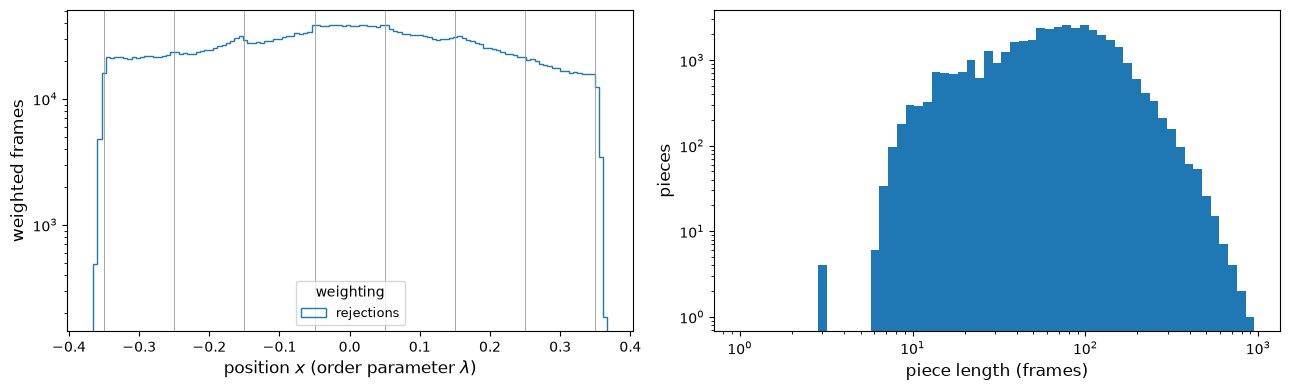

In [5]:
def prepare(weighting):
    parser = argparse.ArgumentParser()
    tis_data.add_data_arguments(parser)
    argv = [TIS_DIR, '--burn-in-fraction', str(BURN_IN_FRACTION), '--thin', str(THIN)]
    if weighting is not None:
        argv += ['--weights', weighting]
    if H5_FILE is not None:
        argv += ['--h5', H5_FILE]
    if LAMBDA_A is not None:
        argv += ['--lambda-a', str(LAMBDA_A)]
    if LAMBDA_B is not None:
        argv += ['--lambda-b', str(LAMBDA_B)]
    if PATHS_PER_ENSEMBLE is not None:
        argv += ['--paths-per-ensemble', str(PATHS_PER_ENSEMBLE)]
    if REVERSED:
        argv += ['--reversed']
    if VELOCITY == 'fd':
        argv += ['--fd-velocity', str(FD_STEPS)]
#    elif VELOCITY == 'recorded':
#        argv += ['--odd-columns', str(V_COLUMN)]     # negated in the mirrored pieces
#    else:
#        raise ValueError("VELOCITY is 'fd' or 'recorded'")
    args = parser.parse_args(argv)
    data = tis_data.prepare_data(args)
    return args.weights, args.lambda_a, args.lambda_b, data     # the weighting actually used


# None = the run's default (section 3); the same weighting twice is fitted once
V_IDX = V_COLUMN - 1 if VELOCITY == 'recorded' else -1      # velocity column of X_all (X_all[:, 0] is x)
names = list(dict.fromkeys(w if w is not None else default_w for w in WEIGHTINGS))
datas = {}
for weighting in names:
    name, lambda_a, lambda_b, data = prepare(weighting)
    datas[name] = data
    print(f'--> {name}: {len(data.lam)} frames, {data.i_traj.max() + 1} pieces, '
          f'{len(np.unique(data.group_traj))} paths\n')
data = next(iter(datas.values()))  # the frames are the same for every weighting
free = ~(data.boundary0 | data.boundary1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
e_lam = np.linspace(data.lam.min(), data.lam.max(), 121)
for name, d in datas.items():
    ax1.hist(d.lam, bins=e_lam, weights=d.path_weights, histtype='step', label=name)
for v in settings['interfaces']:
    ax1.axvline(v, color='0.6', lw=0.6)
ax1.set(xlabel=LABEL, ylabel='weighted frames', yscale='log')
ax1.legend(title='weighting')
lengths = np.bincount(data.i_traj)
ax2.hist(lengths, bins=np.logspace(0, np.log10(lengths.max() + 1), 60))
ax2.set(xscale='log', yscale='log', xlabel='piece length (frames)', ylabel='pieces')
fig.tight_layout()
plt.show()

## 5. Reference Committor (optional)

With `REF_FILE`, the brute-force q(x, v) of the same system (interpolated, clipped to its grid) is the reference for the progress line and the plots: q_exact(frame) = q(x, `V_SCALE` × velocity). The reference is only meaningful if the potential, friction, temperature and the velocity units are the ones of the run. Without it (`REF_FILE = None`) the fits are judged by the convergence metrics (`zqs_z`) and the plots.


In [6]:
if REF_FILE is None:
    q_exact_of = None
else:
    ref = np.load(REF_FILE)
    f_ref = RegularGridInterpolator((ref['xs'], ref['vs']), ref['m'], bounds_error=False, fill_value=None)

    def q_exact_of(X):
        xs, v = X[:, 0], X[:, V_IDX] * V_SCALE
        return np.clip(f_ref(np.c_[np.clip(xs, ref['xs'][0], ref['xs'][-1]), np.clip(v, ref['vs'][0], ref['vs'][-1])]), 0, 1)
    print('reference q(x, v) from', REF_FILE)


reference q(x, v) from /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/1d_cos_well/exact/q_exact_ASE.npz


## 6. Fit the Committor

`CommittorNE` with `group_traj` (the pieces of one path count as one unit in the error estimates), the **A/B ends as traps** and the **stopped ends** (`STOPPED_ENDS`), as in `infretis_staple_1d.ipynb`. Time reversal flips the velocity, so the equilibrium estimator does not apply and the non-equilibrium `CommittorNE` is used.

**Two fits** (cells 6a and 6b), each with every weighting and seed:
- **History, x only** (`HISTORY`): the only CV is the position. Each iteration draws a lag d from `HISTORY` (0 = none) and the basis is a polynomial in (q(t), x(t)) for d = 0 and (x(t−d), x(t)) otherwise (`history_type='y(t-d),y(t)'`; the first d frames of a piece see x(t−d) = 0). With one frame per step this contains the finite-difference velocity, so the committor can depend on v through the history alone.
- **x and v, no history**: the CVs are the position and the velocity (recorded, or the finite difference); each iteration draws one of them, with the usual basis in (q, y).

The first cell below defines the plots, the progress line and the piece ends; `run_fit` (cell 6) fits one variant; cells 6a and 6b call it. Plots go to `<OUT>/<variant>/<weighting>/seed<s>/it<N>_<plot>.png`; **convergence is `zqs_z` about 2 or less** with a small `|dx|`.


In [7]:
def edges_for(d):
    return (np.linspace(lambda_a, lambda_b, N_BINS + 1),)


def extras_for(d, qe):
    # q -> figure: the path-weighted mean q per lambda bin, against the exact committor
    edges = edges_for(d)
    fr = ~(d.boundary0 | d.boundary1)
    bm = seed_runs.BinnedMean((d.lam,), edges[:1], fr)
    w_mean = bm(d.path_weights)
    mid = (edges[0][1:] + edges[0][:-1]) / 2
    prof_ex = None if qe is None else bm(d.path_weights * qe) / w_mean

    def q_profile(q):
        P = bm(d.path_weights * cp.asnumpy(q.r_traj)) / w_mean
        fig, axes = plt.subplots(1, 1 if qe is None else 2, figsize=(6 if qe is None else 13, 4), squeeze=False)
        axes[0, 0].plot(mid, P, label='fit')
        if qe is not None:
            axes[0, 0].plot(mid, prof_ex, 'k--', label='exact')
            t = (prof_ex > 0.05) & (prof_ex < 0.95)
            axes[0, 1].plot(mid, P - prof_ex)
            axes[0, 1].axhline(0, color='k', lw=0.8)
            axes[0, 1].set(xlabel=XLABEL, ylabel='fit $-$ exact',
                           title=f'RMS per bin (0.05 < exact < 0.95) {np.sqrt(np.nanmean((P - prof_ex)[t] ** 2)):.4f}')
            axes[0, 1].grid(alpha=0.3)
        axes[0, 0].set(xlabel=XLABEL, ylabel='$q$ (mean per bin)')
        axes[0, 0].legend()
        axes[0, 0].grid(alpha=0.3)
        fig.tight_layout()
        return fig

    extras = {'q_profile': q_profile}
    return extras


def report_for(d, qe):
    # progress line: path-weighted RMS(fit - exact) over the frames with 0.05 < q_exact < 0.95
    if qe is None:
        return None
    trans = ~(d.boundary0 | d.boundary1) & (qe > 0.05) & (qe < 0.95)
    idx, qe_g, w_g = (cp.asarray(a) for a in (np.flatnonzero(trans), qe[trans], d.path_weights[trans]))

    def report(q):
        diff = q.r_traj[idx] - qe_g
        return f'| RMS(fit - exact) {float(cp.sqrt(cp.sum(w_g * diff * diff) / cp.sum(w_g))):.4f}'
    return report


XLABEL = LABEL

# ---- piece ends: in A or B (trap), or stopped by the path's own end, a turn (stopped end)
# (the frames are the same for every weighting, so this is done once)
b_all = data.boundary0 | data.boundary1
piece_end = np.r_[np.flatnonzero(np.diff(data.i_traj)), len(data.i_traj) - 1]      # last frame of every piece
stop_end = np.zeros(len(b_all), bool)
stop_end[piece_end] = ~b_all[piece_end]
longest = int(np.bincount(data.i_traj - data.i_traj.min()).max())
TRAP_LEN = max(2 ** 16, longest + 2 ** 15 + 1)         # A/B trap: longer than any piece plus the longest Z_q lag (2^15)
print(f'{len(piece_end)} pieces: {stop_end.sum()} end at a turn (stopped), {len(piece_end) - stop_end.sum()} in A or B; '
      f'longest piece {longest} frames, A/B trap {TRAP_LEN}')

PRINT_STEP = min(500, CHUNK, WARMUP_ITER or CHUNK)    # the metrics are recorded every PRINT_STEP iterations (a plot needs a record)
METRICS = ['delta_r2', 'max_z_zq_stopped', 'delta_x']


def show_stage(q, folder, n_done, stage, extras, report):
    """Save and show the plots after a stage (<folder>/it<N>_<plot>.png), and print the progress."""
    seed_runs.save_and_show(q, folder, f'it{n_done}', PLOTS, dict(metrics=METRICS), extras)
    print(f'{n_done} iterations ({stage}) {"" if report is None else report(q)}', flush=True)


39162 pieces: 11591 end at a turn (stopped), 27571 in A or B; longest piece 947 frames, A/B trap 65536


In [8]:
fit_kw = dict(ny=NY, print_step=PRINT_STEP, lazy_basis=LAZY_BASIS, save_min_metric='max_z_zq_stopped',
              metrics_print=('iter', 'delta_r2', 'max_z_zq_stopped', 'max_sd_zq_stopped', 'delta_x', 'time_elapsed'))
fits = {}                                      # (variant, weighting) -> final q per seed, reference, fit time, zqs_z history


def run_fit(variant, name, cv_cols, history, max_iter):
    """One fit on the frames of weighting `name`. The CVs are the columns `cv_cols` of X_all (v scaled by V_SCALE), one drawn
    at random per iteration; `history`: lags d drawn per iteration (None: no history)."""
    d = datas[name]
    qe = q_exact_of(d.X_all) if q_exact_of is not None else None
    X = d.X_all[:, cv_cols].astype(float)
    ncol = d.X_all.shape[1]
    for k, cc in enumerate(cv_cols):
        if cc % ncol == V_IDX % ncol:
            X[:, k] *= V_SCALE
    X_cv = cp.asarray(X)
    extras, report = extras_for(d, qe), report_for(d, qe)
    kw = dict(fit_kw)
    if history:
        kw.update(history_delta_t=list(history), history_type='y(t-d),y(t)')

    def comp_y():
        return X_cv[:, np.random.randint(X_cv.shape[1])]

    t0 = time.time()
    results = {}
    for seed in SEEDS:
        print(f'===== {variant}, weighting {name}, seed {seed} =====', flush=True)
        np.random.seed(seed)
        cp.random.seed(seed)
        folder = f'{OUT}/{variant}/{name}/seed{seed}'
        q = optimalrcs.CommittorNE(boundary0=d.boundary0, boundary1=d.boundary1, i_traj=d.i_traj, t_traj=d.t_traj,
                                   path_weights=d.path_weights, group_traj=d.group_traj)
        q.set_fixed_traj_length_trap(b_all, TRAP_LEN if STOPPED_ENDS else 2 ** 16)
        if STOPPED_ENDS:
            q.set_stopped_traj_end(stop_end)
        n_done = 0
        if WARMUP_ITER:
            optimalrcs.envelope_scale = WARMUP_ENVELOPE
            q.fit_transform(comp_y, gamma=GAMMA, max_iter=WARMUP_ITER, **kw)
            n_done += WARMUP_ITER
            show_stage(q, folder, n_done, f'warm-up, envelope {WARMUP_ENVELOPE}', extras, report)
        optimalrcs.envelope_scale = ENVELOPE
        while n_done < WARMUP_ITER + max_iter:
            n_iter = min(CHUNK, WARMUP_ITER + max_iter - n_done)
            q.fit_transform(comp_y, gamma=GAMMA, max_iter=n_iter, **kw)
            n_done += n_iter
            show_stage(q, folder, n_done, f'main, envelope {ENVELOPE}', extras, report)
        results[seed] = cp.asnumpy(q.r_traj)
        np.save(f'{folder}/q_traj.npy', results[seed].astype(np.float32))
        zqs_z = np.array([float(v) for v in q.metrics_history['max_z_zq_stopped']])
        del q
        cp.get_default_memory_pool().free_all_blocks()
    del X_cv
    fits[(variant, name)] = dict(r=results, q_exact=qe, t_fit=time.time() - t0, zqs_z=zqs_z, weighting=name, variant=variant)


### 6a. Fit A: x only, with histories

In [18]:
# Fit A: x only, with histories (lag d drawn from HISTORY each iteration)
for name in datas:
    run_fit('history_x', name, cv_cols=[0], history=HISTORY, max_iter=MAX_ITER_HIST)


[[-0.348909]
 [-0.344053]
 [-0.338806]
 ...
 [ 0.341049]
 [ 0.346652]
 [ 0.35236 ]]
===== history_x, weighting rejections, seed 0 =====

Training interrupted at iteration 467; keeping the RC of the last completed update.


KeyError: 'iter'

Error in callback <function flush_figures at 0x7f7d67aa2e50> (for post_execute), with arguments args (),kwargs {}:


KeyboardInterrupt: 

### 6b. Fit B: x and v as CVs, no history

[[-0.348909  0.877998]
 [-0.344053  1.046415]
 [-0.338806  1.107668]
 ...
 [ 0.341049 -1.089179]
 [ 0.346652 -1.130859]
 [ 0.35236  -1.175701]]
===== x_v, weighting rejections, seed 0 =====
#=500, dr2=1109.54, zqs_z=47.5551, sdzqs=1065.28, |dx|=0.461022, time=5.54872
#=1000, dr2=1116.77, zqs_z=47.5782, sdzqs=1052.11, |dx|=0.00321538, time=11.019
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/1d_cos_well/infretis_langevin_staple/production_seed/x_v/rejections/seed0/it1000 ---


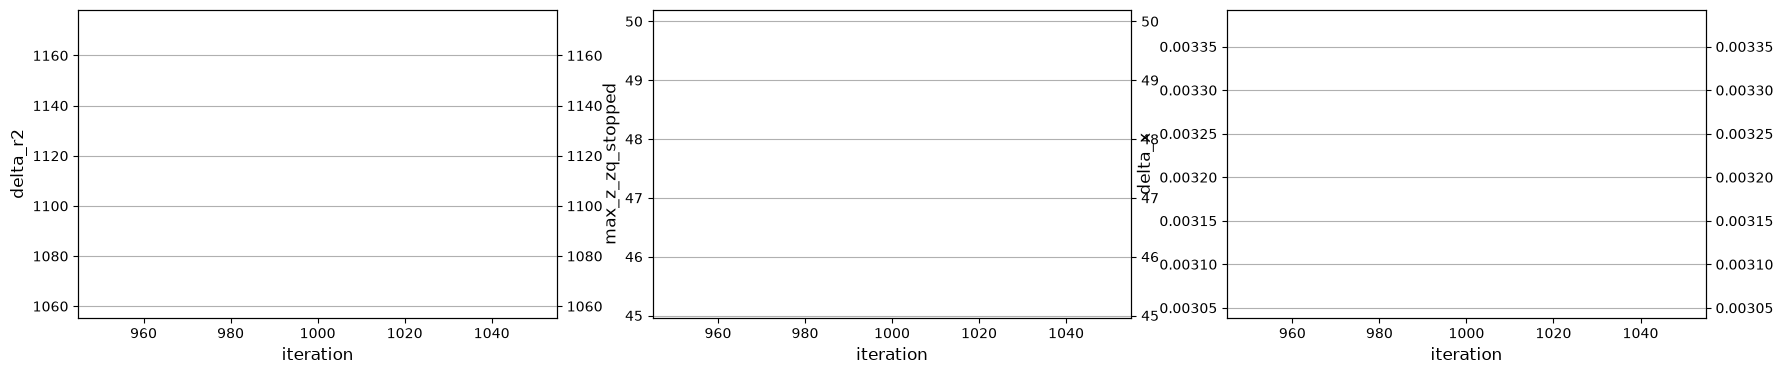

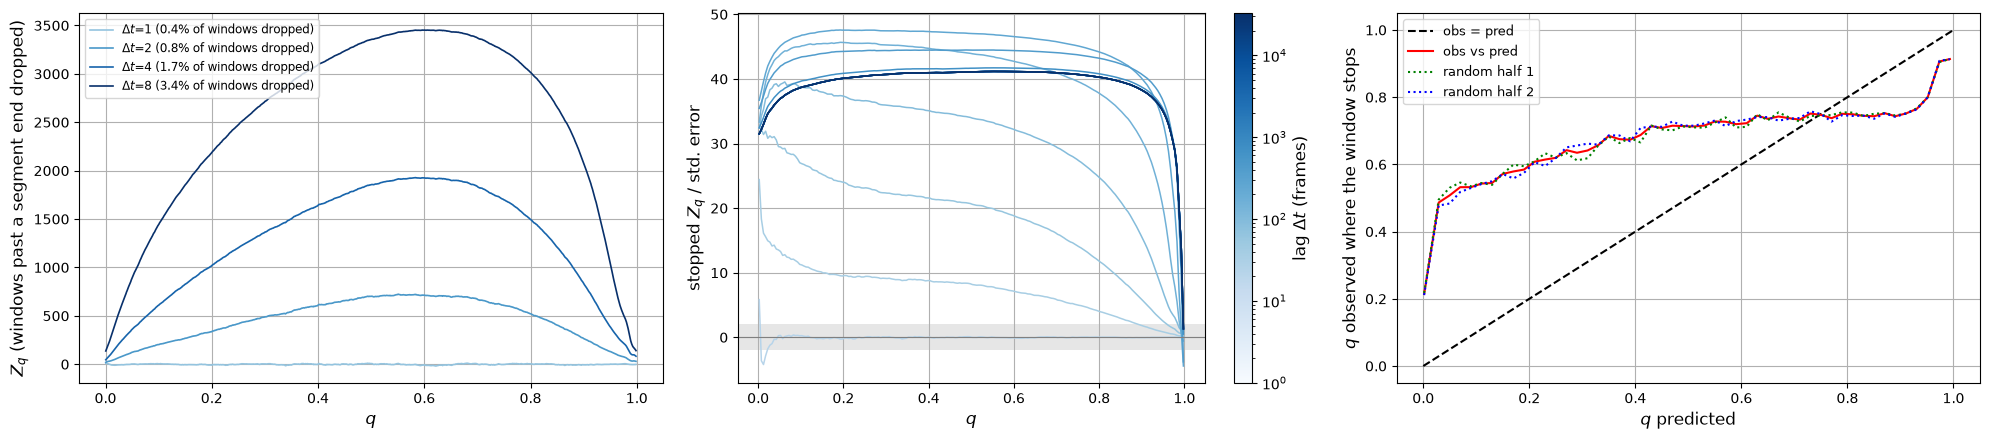

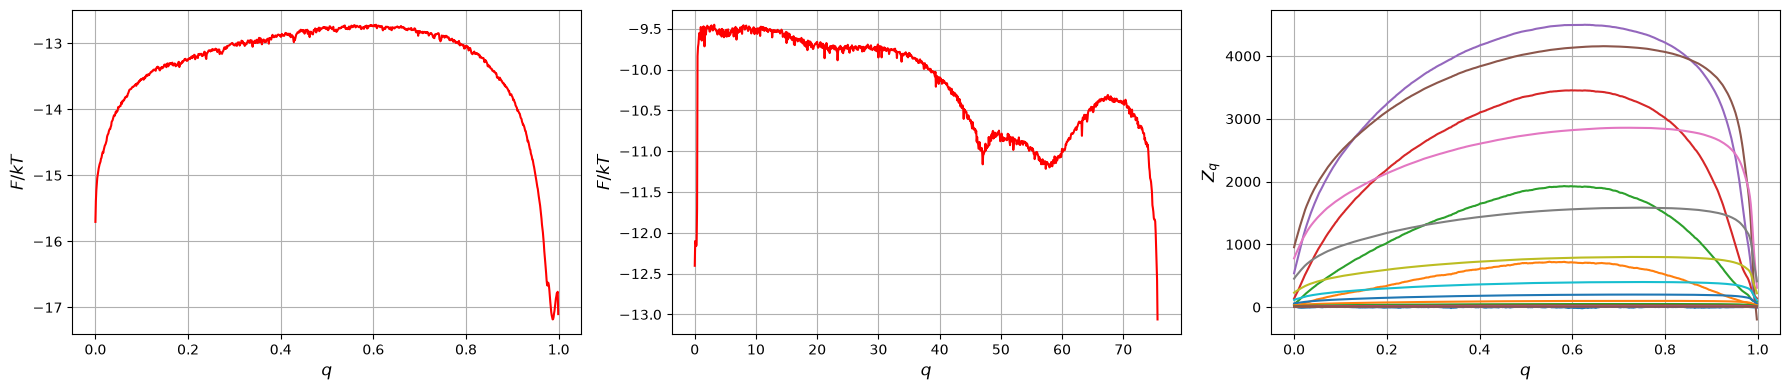

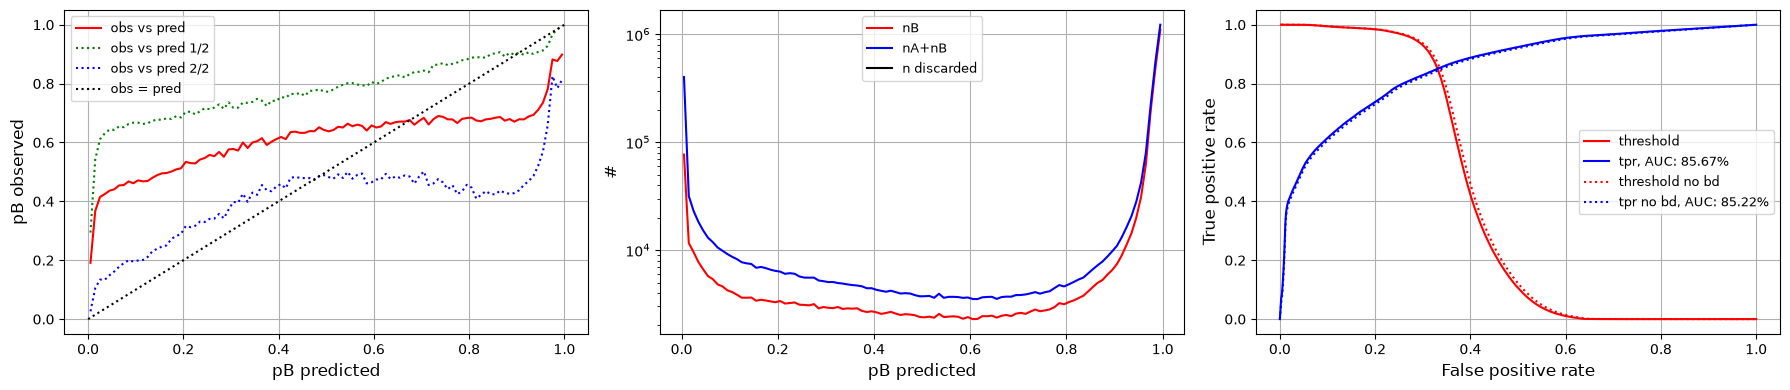

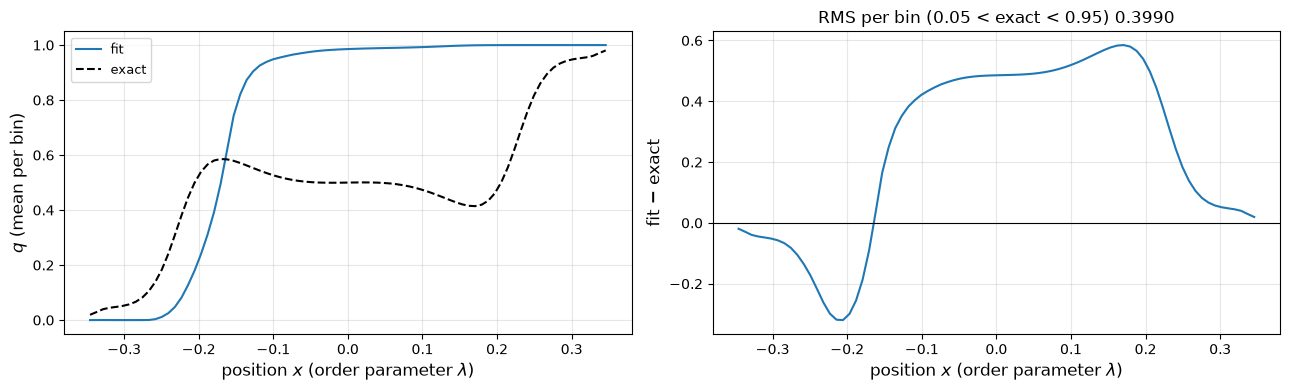

1000 iterations (warm-up, envelope 1) | RMS(fit - exact) 0.4225

Training interrupted at iteration 1500; keeping the RC of the last completed update.
Error in callback <function _draw_all_if_interactive at 0x7fc39aaa03b0> (for post_execute), with arguments args (),kwargs {}:



KeyboardInterrupt



KeyboardInterrupt: 

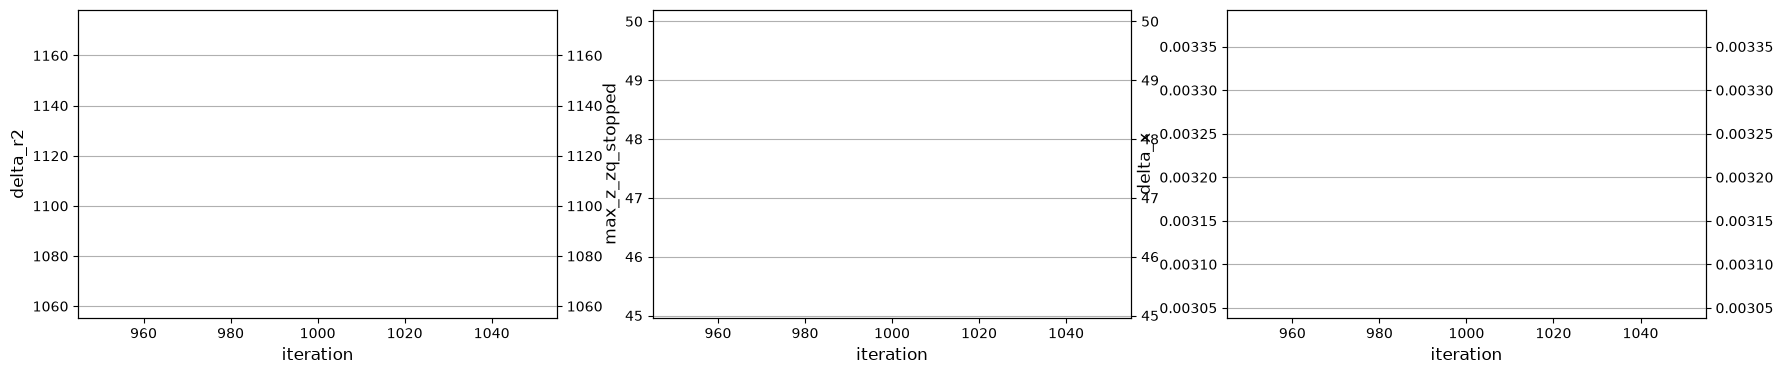

In [10]:
# Fit B: x and v as CVs, no history
for name in datas:
    run_fit('x_v', name, cv_cols=[0, 2], history=None, max_iter=MAX_ITER_XV)


## 7. Results

**Table:** per variant, weighting and seed, the data size, the final and lowest `zqs_z` (about 2 or less is consistent) and, with a reference, the path-weighted RMS of fit − exact over the frames with 0.05 < q_exact < 0.95.

**q along x:** the path-weighted mean q per x bin of every fit (and the reference, dashed), and fit − reference. **q in the (x, v) plane:** the mean q per (x, v) bin of every fit; if the velocity matters, q rises with v towards B at fixed x.


In [ ]:
rows, profiles = [], {}
for (variant, name), fit in fits.items():
    d = datas[name]
    fr = ~(d.boundary0 | d.boundary1)
    edges = edges_for(d)
    bm = seed_runs.BinnedMean((d.lam,), edges[:1], fr)
    w_mean = bm(d.path_weights)
    qe = fit['q_exact']
    for s, r in fit['r'].items():
        row = dict(variant=variant, weighting=name, seed=s, paths=len(np.unique(d.group_traj)), frames=len(r),
                   zqs_z_final=fit['zqs_z'][-1], zqs_z_min=fit['zqs_z'][1:].min(), fit_minutes=fit['t_fit'] / 60 / len(fit['r']))
        profiles[(variant, name, s)] = bm(d.path_weights * r) / w_mean
        if qe is not None:
            t = fr & (qe > 0.05) & (qe < 0.95)
            row['rms_frames'] = np.sqrt(np.sum(d.path_weights[t] * (r[t] - qe[t]) ** 2) / np.sum(d.path_weights[t]))
            profiles[('exact', name, 0)] = bm(d.path_weights * qe) / w_mean
        rows.append(row)
summary = pd.DataFrame(rows).set_index(['variant', 'weighting', 'seed'])
os.makedirs(OUT, exist_ok=True)
summary.to_csv(f'{OUT}/summary.csv')
display(summary.round(4))

mid = (edges[0][1:] + edges[0][:-1]) / 2
has_exact = any(k[0] == 'exact' for k in profiles)
fig, axes = plt.subplots(2 if has_exact else 1, 1, figsize=(9, 7 if has_exact else 4), sharex=True, squeeze=False)
for (variant, name, s), P in profiles.items():
    if variant == 'exact':
        continue
    axes[0, 0].plot(mid, P, label=f'{variant}, {name}, seed {s}')
    if has_exact:
        axes[1, 0].plot(mid, P - profiles[('exact', name, 0)], label=f'{variant}, {name}, seed {s}')
if has_exact:
    axes[0, 0].plot(mid, profiles[('exact', next(iter(fits.values()))['weighting'], 0)], 'k--', label='reference')
    axes[1, 0].axhline(0, color='k', lw=0.8); axes[1, 0].set(ylabel='fit $-$ reference'); axes[1, 0].grid(alpha=0.3)
axes[0, 0].set(ylabel='$q$ (mean per bin)'); axes[0, 0].legend(); axes[0, 0].grid(alpha=0.3)
axes[-1, 0].set(xlabel=XLABEL)
fig.tight_layout(); fig.savefig(f'{OUT}/profiles.png', dpi=110); plt.show()


**q in the (x, v) plane.** Mean q per (x, v) bin (bins with at least 20 frames) for every fit and seed, outside A and B; with a reference, the same for the reference and fit − reference.

In [ ]:
d0 = datas[next(iter(datas))]
fr0 = ~(d0.boundary0 | d0.boundary1)
xs_, vs_ = d0.X_all[:, 0], d0.X_all[:, V_IDX] * V_SCALE
e_x = np.linspace(lambda_a, lambda_b, 36)
e_v = np.linspace(*np.quantile(vs_[fr0], [0.005, 0.995]), 36)
n_b = np.histogram2d(xs_[fr0], vs_[fr0], [e_x, e_v])[0]
bmap = lambda val: np.where(n_b >= 20, np.histogram2d(xs_[fr0], vs_[fr0], [e_x, e_v], weights=val[fr0])[0] / np.maximum(n_b, 1), np.nan)
panels = []
for (variant, name), fit in fits.items():
    for s, r in fit['r'].items():
        panels.append((f'{variant}, {name}, seed {s}', bmap(r), 'coolwarm', (0, 1)))
        if fit['q_exact'] is not None:
            panels.append(('reference', bmap(fit['q_exact']), 'coolwarm', (0, 1)))
            panels.append(('fit - reference', bmap(r - fit['q_exact']), 'PuOr', (-0.15, 0.15)))
ncol = 3 if any(f['q_exact'] is not None for f in fits.values()) else min(2, len(panels))
nrow = int(np.ceil(len(panels) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(5.5 * ncol, 4 * nrow), squeeze=False)
for ax, (title, m, cmap, lim) in zip(axes.ravel(), panels):
    im = ax.pcolormesh(e_x, e_v, m.T, cmap=cmap, vmin=lim[0], vmax=lim[1])
    ax.set(title=title, xlabel='x', ylabel='v'); fig.colorbar(im, ax=ax)
for ax in axes.ravel()[len(panels):]:
    ax.axis('off')
fig.tight_layout(); fig.savefig(f'{OUT}/q_x_v.png', dpi=110); plt.show()


## 8. Save

Every fit's q per frame with its frames, in the format of `load_tis_data_cupy.py`'s `committor.npz`, as `<OUT>/<variant>/<weighting>/seed<s>/committor.npz`.

In [ ]:
for (variant, name), fit in fits.items():
    d = datas[name]
    for s, r in fit['r'].items():
        path = f'{OUT}/{variant}/{name}/seed{s}/committor.npz'
        np.savez(path, r=r, lam=d.lam, X_all=d.X_all, i_traj=d.i_traj, t_traj=d.t_traj, group_traj=d.group_traj,
                 path_weights=d.path_weights, boundary0=d.boundary0, boundary1=d.boundary1, weighting=name, variant=variant,
                 tis_dir=TIS_DIR)
        print('saved', path)
